# Groundwater Recharge and GRACE Anomalies with AquaScope

This notebook walks through AquaScope's groundwater module: estimating recharge from well data, analysing an aquifer pumping test, and tracking regional storage change from GRACE satellite anomalies. 

Note : All data are synthetic.

**Contents:**
1. Simulating GRACE-like total-water-storage anomalies
2. Estimating recharge
3. Aquifer hydraulics: a pumping test (Theis)
4. Plotting trends in groundwater storage 


**Prerequisites:**
pip install aquascope[all]

## 1.  Simulating GRACE-like total-water-storage anomalies
Here we build 20 years of monthly series (2006–2025) with:
- A hidden trend of −10 mm/year in TWS,
- A seasonal cycle in each component,
- Some random noise, larger for GRACE than for the models.

`tws`, `sm` and `sw` are the total water storage, soil-moisture and surface-water anomalies, in mm.

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
#Generate synthetic monthly GRACE-like series (20 years)
rng = np.random.default_rng(42)
months = 12 * 20
dates_grace = pd.date_range("2006-01-01", periods= months, freq="MS")
t_years = np.arange(months) / 12
#tws = Total Water Storage; sm = Soil moisture anomaly ;sw = Surface water anomaly 
tws = -10 * t_years + 55 * np.sin(2 * np.pi * t_years) + rng.normal(0, 4, months)
sm  = 22 * np.sin(2 * np.pi * t_years - 0.6) + rng.normal(0, 3, months)
sw  =  8 * np.sin(2 * np.pi * t_years - 0.2) + rng.normal(0, 1, months)

tws = pd.Series(tws, index=dates_grace, name="tws")
sm  = pd.Series(sm,  index=dates_grace, name="sm")
sw  = pd.Series(sw,  index=dates_grace, name="sw")


print(f"TWS: {tws.min():.1f} to {tws.max():.1f} mm, mean={tws.mean():.1f}")


TWS: -253.2 to 56.3 mm, mean=-99.8


## 2. Estimating recharge
**Recharge** is the water that infiltrates through the soil and reaches the water table. It cannot be measured directly, so it is estimated.
To make the estimation, AquaScope offers several approaches:

**- Water Table Fluctuation (WTF)**: converts water-level rises in an observation well into recharge. Suited to unconfined aquifers.
**- Chloride Mass Balance (CMB)**: infers recharge from the concentration of chloride in rain and groundwater.
**- Baseflow separation**: uses the groundwater share of river flow as a recharge proxy.
**- Soil water balance**: tracks water entering, leaving and stored in the root zone.

This notebook demonstrates the WTF method.

WTF recharge: 146.4 mm/year
Total rise: 7.32 m over 5.0 years


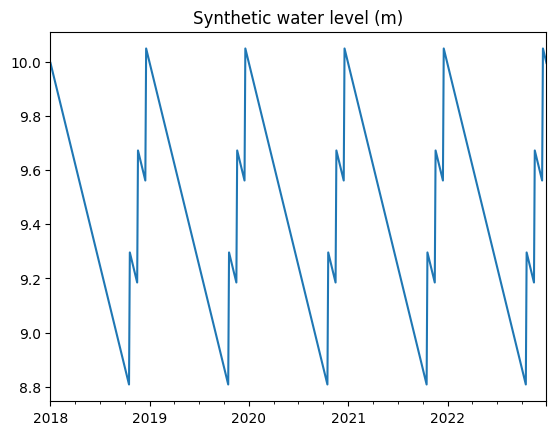

In [30]:
from aquascope.groundwater import water_table_fluctuation

# Generate synthetic daily water levels for 5 years without noise
dates_gw = pd.date_range("2018-01-01", "2022-12-31", freq="D")
change = np.full(len(dates_gw), -1.5 / 365)      
for k in range(5):                                
    for day in (290, 320, 350):                   
        i = k * 365 + day
        change[i:i + 3] += 0.5 / 3                

levels = pd.Series(10 + np.cumsum(change), index=dates_gw, name="level_m")
levels.plot(title="Synthetic water level (m)");
wtf = water_table_fluctuation(levels, specific_yield=0.1)
print(f"WTF recharge: {wtf.value_mm_per_year:.1f} mm/year")
print(f"Total rise: {wtf.metadata['total_rise_m']:.2f} m over {wtf.metadata['period_years']:.1f} years")


## 3. Aquifer Hydraulics: a Pumping Test

In a pumping test, water is pumped at a constant rate and the `drawdown` is measured in a nearby observation well. The drawdown curve reveals two properties of the aquifer:

- **Transmissivity (T)**: how easily the aquifer transmits water (m²/day)
- **Storativity (S)**: how much water the aquifer releases as pressure drops (dimensionless)

We simulate a test with T = 500 m²/day, S = 0.001, Q = 2000 m³/day and an observation well at 100 m, then check that AquaScope recovers these values:
- `theis_drawdown`: exact Theis solution
- `cooper_jacob`: straight-line approximation, valid only at late times (u < 0.01, i.e. t > 0.5 day here)
- `estimate_transmissivity`: inverts noisy observations to recover T and S
- `safe_yield`: compares recharge from section 2 with extraction, to check whether pumping is sustainable 

Drawdown after 1 day: 1.50 m
Estimated T=497 m²/day (true 500), S=0.00102 (true 0.001)
Extraction/recharge = 1.09 -> unsustainable


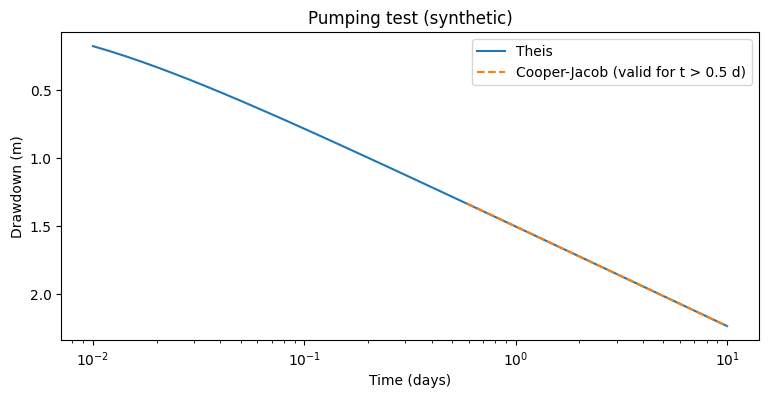

In [31]:
from aquascope.groundwater import theis_drawdown, cooper_jacob, estimate_transmissivity, safe_yield

# Pumping test: T=500 m²/day, S= 0.001, Q=2000 m³/day, observation well at 100 m
T, S, Q, r = 500, 1e-3, 2000, 100
t = np.logspace(-2, 1, 40)                       

s_theis = theis_drawdown(T, S, Q, r, t)
print(f"Drawdown after 1 day: {theis_drawdown(T, S, Q, r, 1.0)[0]:.2f} m")

# Cooper-Jacob is valid only when u = r²S/(4Tt) < 0.01, so t > 0.5 day here
late = t > 0.5
s_cj = cooper_jacob(T, S, Q, r, t[late])
#Add a weak measurement of noise
obs = s_theis + rng.normal(0, 0.01, len(t))      
est = estimate_transmissivity(t[late], obs[late], Q, r, method="cooper_jacob")
print(f"Estimated T={est.transmissivity:.0f} m²/day (true {T}), S={est.storativity:.5f} (true {S})")

sy_res = safe_yield(area_km2=35_000, recharge_mm=wtf.value_mm_per_year, current_extraction_mm=160)
print(f"Extraction/recharge = {sy_res.ratio:.2f} -> {sy_res.assessment}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogx(t, s_theis, label="Theis")
ax.semilogx(t[late], s_cj, "--", label="Cooper-Jacob (valid for t > 0.5 d)")
ax.invert_yaxis(); ax.set_xlabel("Time (days)"); ax.set_ylabel("Drawdown (m)")
ax.set_title("Pumping test (synthetic)"); ax.legend();

## 4. Plotting Trends in Groundwater Storage
 **GRACEProcessor** turns the three series from section 1 into groundwater storage (GWS = TWS − SM − SW), then:

- `depletion_rate` : fits a linear trend and gives the rate in mm/year and km³/year, with a 95% confidence interval.
**Note**: the negative rate means the aquifer is losing water.

- `trend_analysis`: returns the fitted trend line for plotting.

- `anomaly_detection`: flags months more than 2 standard deviations away from normal.


Depletion: -10.1 mm/yr (95% CI -10.7 to -9.6)
Volume: -0.36 km³/yr
3 anomalous months


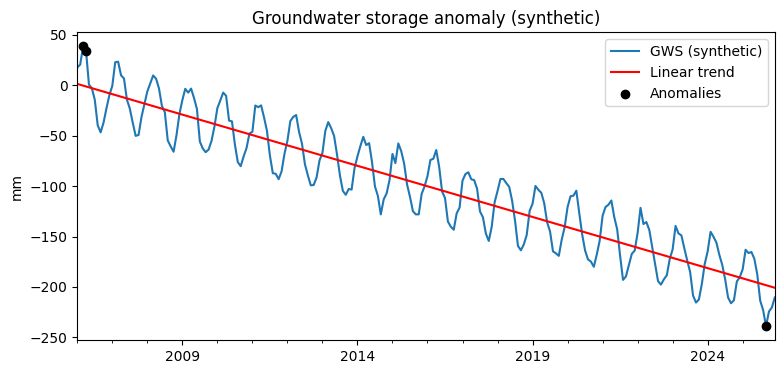

In [32]:
from aquascope.groundwater import GRACEProcessor

proc = GRACEProcessor(area_km2=35_000)
res = proc.compute_gws(tws, sm, sw)
dep = proc.depletion_rate(res.gws)
lo, hi = dep.confidence_interval
print(f"Depletion: {dep.rate_mm_per_year:.1f} mm/yr (95% CI {lo:.1f} to {hi:.1f})")
print(f"Volume: {dep.rate_km3_per_year:.2f} km³/yr")

tr = proc.trend_analysis(res.gws)
anoms = proc.anomaly_detection(res.gws, threshold_sigma=2.0)
print(f"{len(anoms)} anomalous months")

ax = res.gws.plot(figsize=(9, 4), label="GWS (synthetic)")
tr.trend_line.plot(ax=ax, color="r", label="Linear trend")
ax.scatter([a.date for a in anoms], [a.value for a in anoms], color="k", zorder=3, label="Anomalies")
ax.set_ylabel("mm"); ax.set_title("Groundwater storage anomaly (synthetic)"); ax.legend();

## Summary

All analysis results are shown above. These tools are also available from the CLI:
```bash
aquascope groundwater --analysis recharge-wtf --file well_level.csv
aquascope groundwater --analysis theis --file well_level.csv
```

In [33]:
!aquascope groundwater --help 

usage: aquascope groundwater [-h]
                             [--analysis {trend,recession,seasonal,hydrograph,recharge-wtf,theis}]
                             [--file FILE] [--bbox W S E N] [--month MONTH]
                             [--mode {level,change}] [--compare COMPARE]
                             [--geojson GEOJSON] [--json]
                             [--specific-yield SPECIFIC_YIELD]
                             [--transmissivity TRANSMISSIVITY]
                             [--storativity STORATIVITY]
                             [--pumping-rate PUMPING_RATE]
                             [--distance DISTANCE] [--output OUTPUT]
                             [{surface}]

positional arguments:
  {surface}             surface: a groundwater-level surface and its change
                        from the Archive's wells

options:
  -h, --help            show this help message and exit
  --analysis {trend,recession,seasonal,hydrograph,recharge-wtf,theis}
                        